# How zero-shot CLIP embeds the six DomainNet domains

**Question.** What does the frozen CLIP image encoder (ViT-B/32, the model Ramen uses on DomainNet) do with the six DomainNet domains?
Does it organise images by **class** (what zero-shot classification needs) or by **domain** (style)? Where in the embedding are the
zero-shot errors, and why is quickdraw at 13% accuracy while real is at 82%?

**What this is.** A descriptive visualisation of cached embeddings, not a method or an experiment with a variant. No GPU, no adaptation.
Every figure answers one question; the finding is in the figure title. Ramen does not appear: everything is about the zero-shot model ($\theta_0$).

**Data.** DomainNet, all 596,006 images, 345 classes, 6 domains (clipart 48,833 · infograph 53,201 · painting 75,759 · quickdraw 172,500 ·
real 175,327 · sketch 70,386). Image features $z_i$ = the cached seed-0 NoAdapt features
(`results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt_feats.npy`, fp16, 512-d); class text embeddings $w_c$ = CLIP text encoder
on the class names with Ramen's prompt templates (cached by `2026-11-21_hubness`). Labels and domains from the cached run.
**Seeds.** A seed only changes stream order; zero-shot features do not depend on it. Subsamples for the 2-D maps use `numpy` seed 0.

**How produced.** `python make_notebook.py`, then executed with `jupyter nbconvert --execute`. Code: `data.py` (loading), `analysis.py`
(all numbers), `plots.py` (one function per figure). Nothing in `src/`, `cfg/` or the shared harness was edited.

**How to read it.** 2-D maps (t-SNE) show who is near whom locally; distances *between* clusters in t-SNE are not meaningful, so every
map is paired with a number computed in the full 512-d space (variance shares, centroid cosines, nearest neighbours, a linear probe).

**Sections.** 1 Setup · 2 Data · 3 Global map · 4 Classes across domains · 5 Domain geometry · 6 Neighbours · 7 Image–text alignment ·
8 Classes × domains · 9 Images · 10 Interpretation · 11 Glossary


## Quantities (mathematical definitions)

Ramen's notation (`references/ramen.md`): $z_i=f_{\theta_0}(x_i)/\lVert f_{\theta_0}(x_i)\rVert_2$, $w_c$ unit-norm text embedding,
zero-shot prediction $\hat y_i=\arg\max_c z_i^\top w_c$ (the logit scale 100 does not change the argmax). Image $i$ has true class $y_i$ and domain $d_i$.
$n_d$, $n_c$, $n_{c,d}$ = image counts.

| quantity | definition | code |
|---|---|---|
| domain mean | $\mu_d=\frac1{n_d}\sum_{i:d_i=d}z_i$; balanced grand mean $\bar\mu=\frac16\sum_d\mu_d$ | `Geometry.domain_means` |
| cell mean | $m_{c,d}=\frac1{n_{c,d}}\sum_{i:y_i=c,d_i=d}z_i$ | `Geometry.cell_means` |
| variance share of a grouping $g$ | $\eta^2_g=\sum_{k} n_k\lVert \bar z_k-\bar z\rVert^2\,/\,\sum_i\lVert z_i-\bar z\rVert^2$, groups $k$ = domains, classes or (class, domain) cells | `Geometry.variance_shares` |
| concentration | mean resultant length $\lVert\mu_d\rVert\in[0,1]$ (1 = every image of the domain points the same way) | `Geometry.concentration` |
| centred centroid similarity | $\cos(\mu_a-\bar\mu,\ \mu_b-\bar\mu)$ | `Geometry.centroid_similarity` |
| cross-domain class agreement | $A_{ab}=\frac1{|\mathcal C_{ab}|}\sum_{c\in\mathcal C_{ab}}\cos(m_{c,a}-\mu_a,\ m_{c,b}-\mu_b)$, $\mathcal C_{ab}$ = classes with $n_{c,a},n_{c,b}\ge20$ | `Geometry.class_agreement` |
| centroid zero-shot accuracy | share of classes $c$ with $\arg\max_k m_{c,d}^\top w_k=c$ ($n_{c,d}\ge20$) | `Geometry.centroid_zero_shot` |
| domain probe | multinomial logistic regression $z\mapsto d$, 5,000 train / 2,000 test images per domain | `domain_probe` |
| neighbour composition | $\mathcal N_{10}(i)$ = 10 nearest images to $z_i$ by cosine among all 596,006 (self excluded); share with $y_j=y_i$ / $d_j=d_i$ | `Neighbours.composition` |
| kNN vote (**oracle**) | $\arg\max_c\#\{j\in\mathcal N_{10}(i):y_j=c\}$, uses the neighbours' **true labels**: class information in the image geometry, not a method | `Neighbours.composition` |
| image–text margin | $\delta_i=z_i^\top w_{y_i}-\max_{c\ne y_i}z_i^\top w_c$; $\delta_i>0\iff$ zero-shot correct | `TextAlignment` |
| domain-centred map | t-SNE of $z_i-\mu_{d_i}$ (domain mean removed) | `Projection(centre_domains=True)` |

Reading guide: if domains were only a **constant offset** ("appearance"), removing $\mu_d$ would make classes line up across domains
($A_{ab}\approx1$) and centroid accuracy would be high everywhere. A low $A_{ab}$ or a low centroid accuracy for a domain means the
class directions themselves move in that domain ("concept" shift, cf. `2026-11-22_shift_decomposition`).


## 1. Setup

In [1]:
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '16')
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 9})
pd.set_option('display.width', 220, 'display.max_columns', 20)

from data import DomainNetEmbeddings
from analysis import (Geometry, Neighbours, Projection, TextAlignment, domain_probe, stratified_sample, top_confusions)
import plots

# ---- knobs ----
PER_DOMAIN   = 1500     # images per domain in the global 2-D maps (balanced)
CLASSES      = ['airplane', 'bicycle', 'cat', 'guitar', 'umbrella', 'tree', 'envelope', 'pillow']  # <= 8, class maps
PER_CELL     = 120      # images per (class, domain) in the class maps
GRID_CLASSES = ['bicycle', 'ocean']   # thumbnails across domains
K            = 10       # nearest neighbours

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data

Images, classes and zero-shot errors per domain; the sanity check recomputes the zero-shot prediction from the cached features (differences come only from the fp16 cache).

In [2]:
d = DomainNetEmbeddings()
display(d.describe())
d.sanity();

domain-averaged zero-shot accuracy 55.37, sample-weighted 52.83 (314,845 of 596,006)


,images,share,classes_present,median_per_class,zero_shot_errors,zero_shot_acc
domain,,,,,,
clipart,48833,8.2%,345,134,"15,505 of 48,833 (31.8%)",68.25
infograph,53201,8.9%,345,108,"29,847 of 53,201 (56.1%)",43.90
painting,75759,12.7%,345,178,"26,835 of 75,759 (35.4%)",64.58
quickdraw,172500,28.9%,345,500,"149,508 of 172,500 (86.7%)",13.33
real,175327,29.4%,345,535,"31,345 of 175,327 (17.9%)",82.12
sketch,70386,11.8%,345,174,"28,121 of 70,386 (40.0%)",60.05


argmax(z·W) == cached NoAdapt prediction on 594,195 of 596,006 images (99.70%; differences come from the fp16 feature cache)


domain-averaged zero-shot accuracy 55.37, sample-weighted 52.83 (314,845 of 596,006)


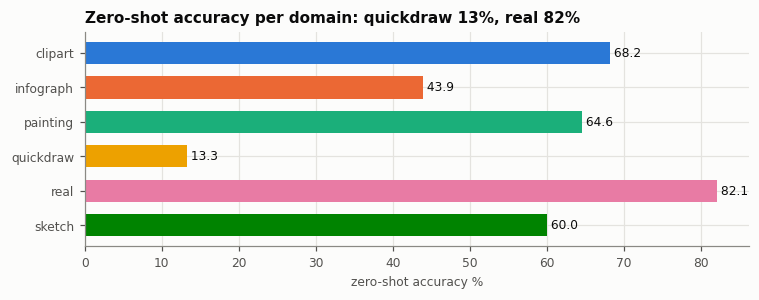

In [3]:
fig = plots.domain_bars(d.describe().zero_shot_acc, 'Zero-shot accuracy per domain: quickdraw 13%, real 82%',
                         'zero-shot accuracy %')

## 3. Global map: does the embedding separate domains or classes?

Balanced sample (PER_DOMAIN images per domain), PCA to 50-d, then t-SNE. Left: raw embedding. The PCA-2D view is the linear (distance-preserving) counterpart.

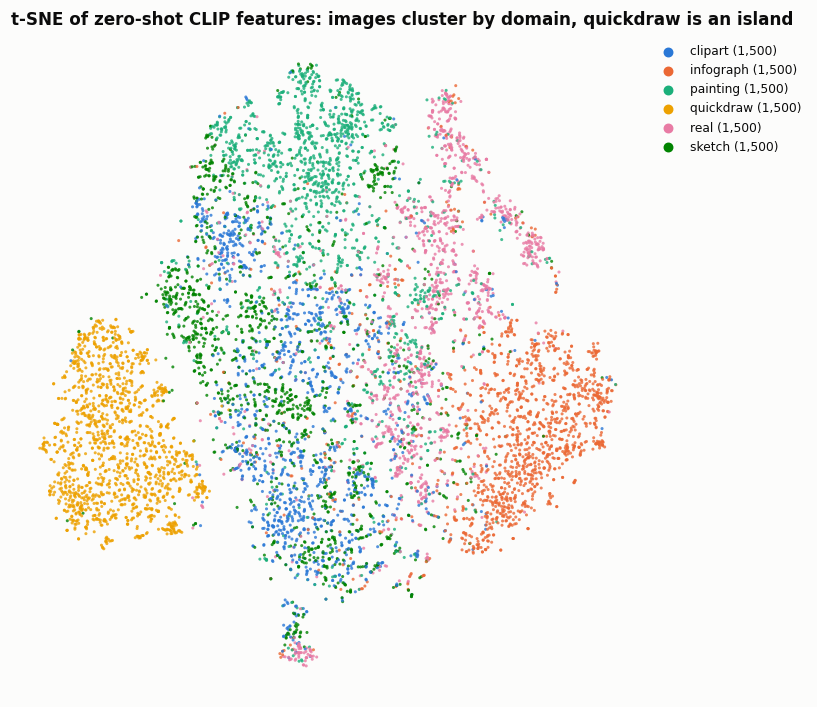

In [4]:
idx = stratified_sample(d, per_domain=PER_DOMAIN)
proj = Projection(d).fit(idx)
fig = plots.scatter_by_domain(proj, d, 't-SNE of zero-shot CLIP features: images cluster by domain, quickdraw is an island')

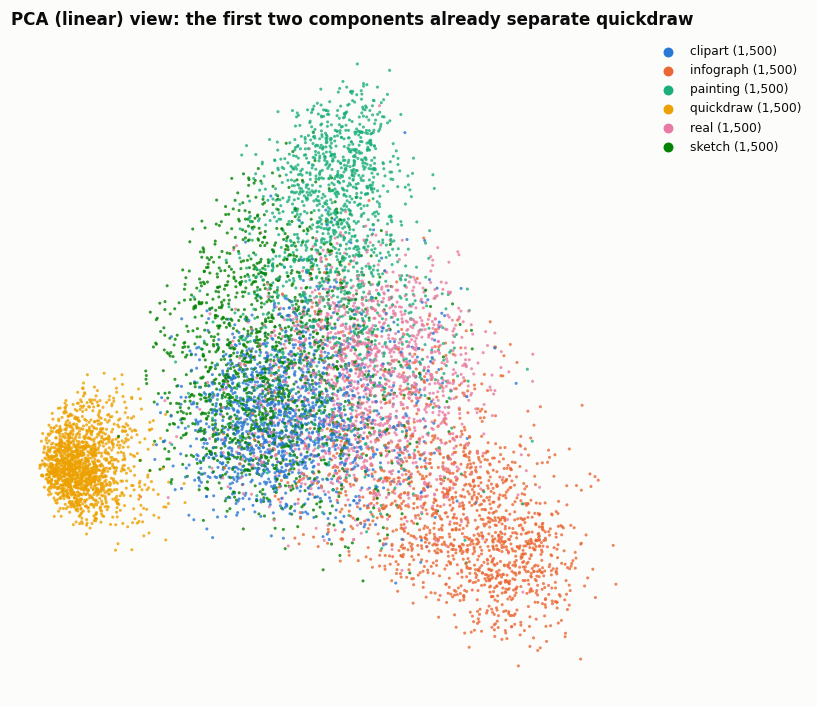

In [5]:
proj_pca = Projection(d, method='pca').fit(idx)
fig = plots.scatter_by_domain(proj_pca, d, 'PCA (linear) view: the first two components already separate quickdraw')

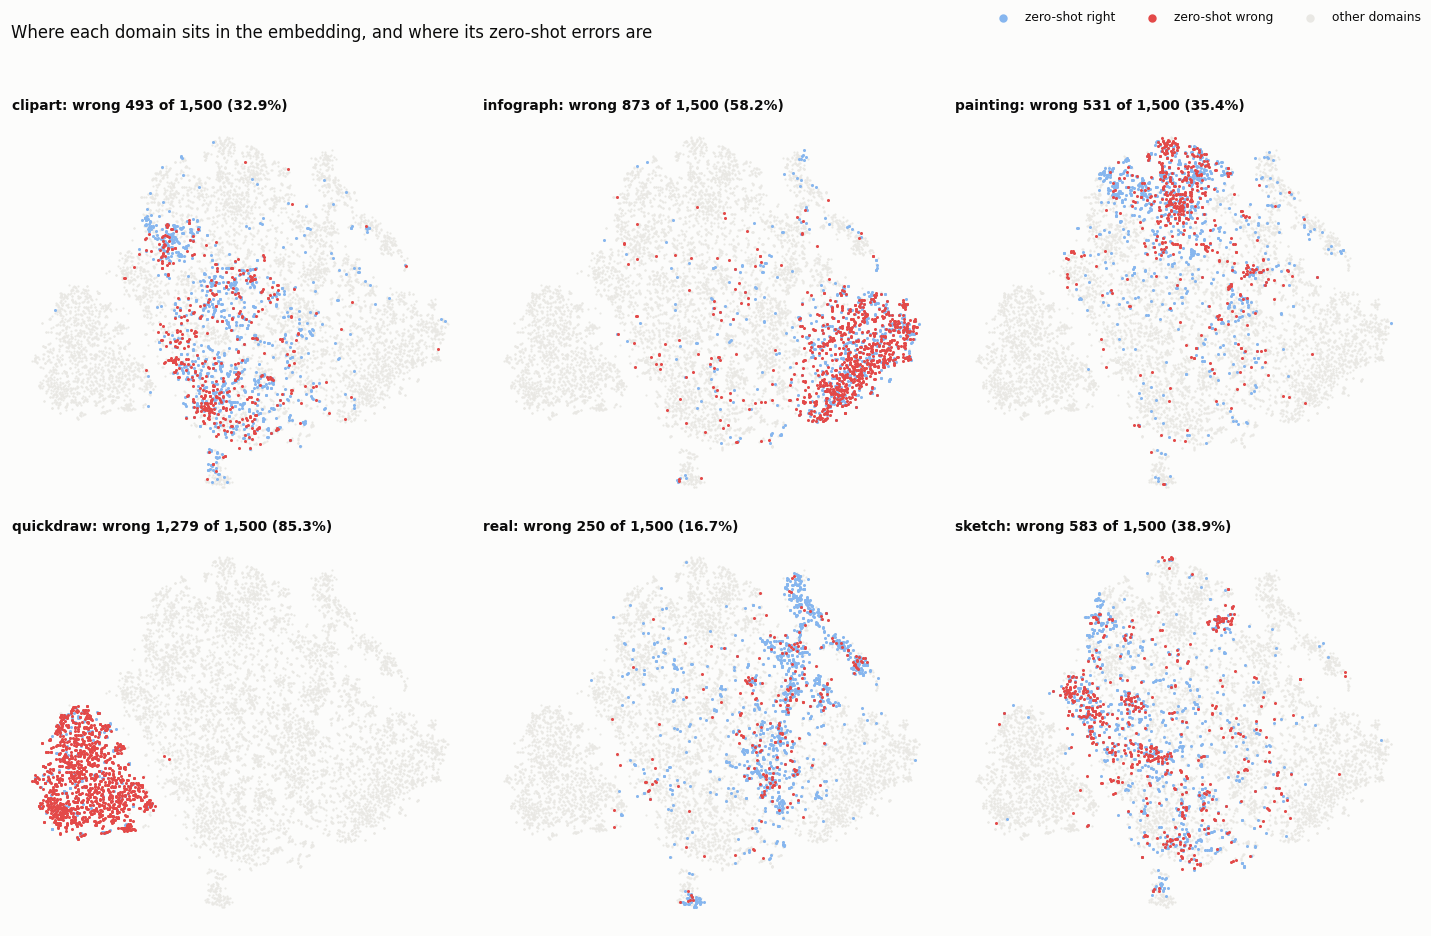

In [6]:
fig = plots.domain_panels(proj, d)

**Domain-centred map.** Same images after subtracting each domain's mean embedding $\mu_d$. If domains were only a constant offset, the domain colours would now mix completely.

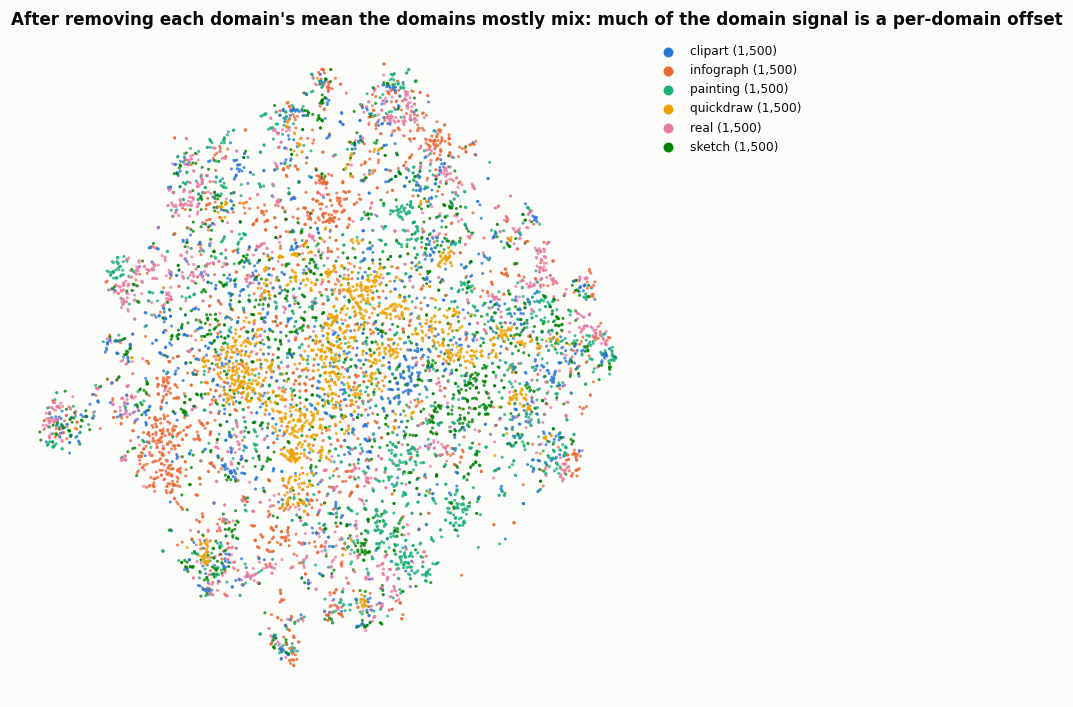

In [7]:
proj_c = Projection(d, centre_domains=True).fit(idx)
fig = plots.scatter_by_domain(proj_c, d, 'After removing each domain\'s mean the domains mostly mix: much of the domain signal is a per-domain offset')

## 4. Classes across domains

The classes in `CLASSES`, up to `PER_CELL` images per (class, domain), one shared t-SNE; one panel per domain. Filled = zero-shot right, hollow = wrong.

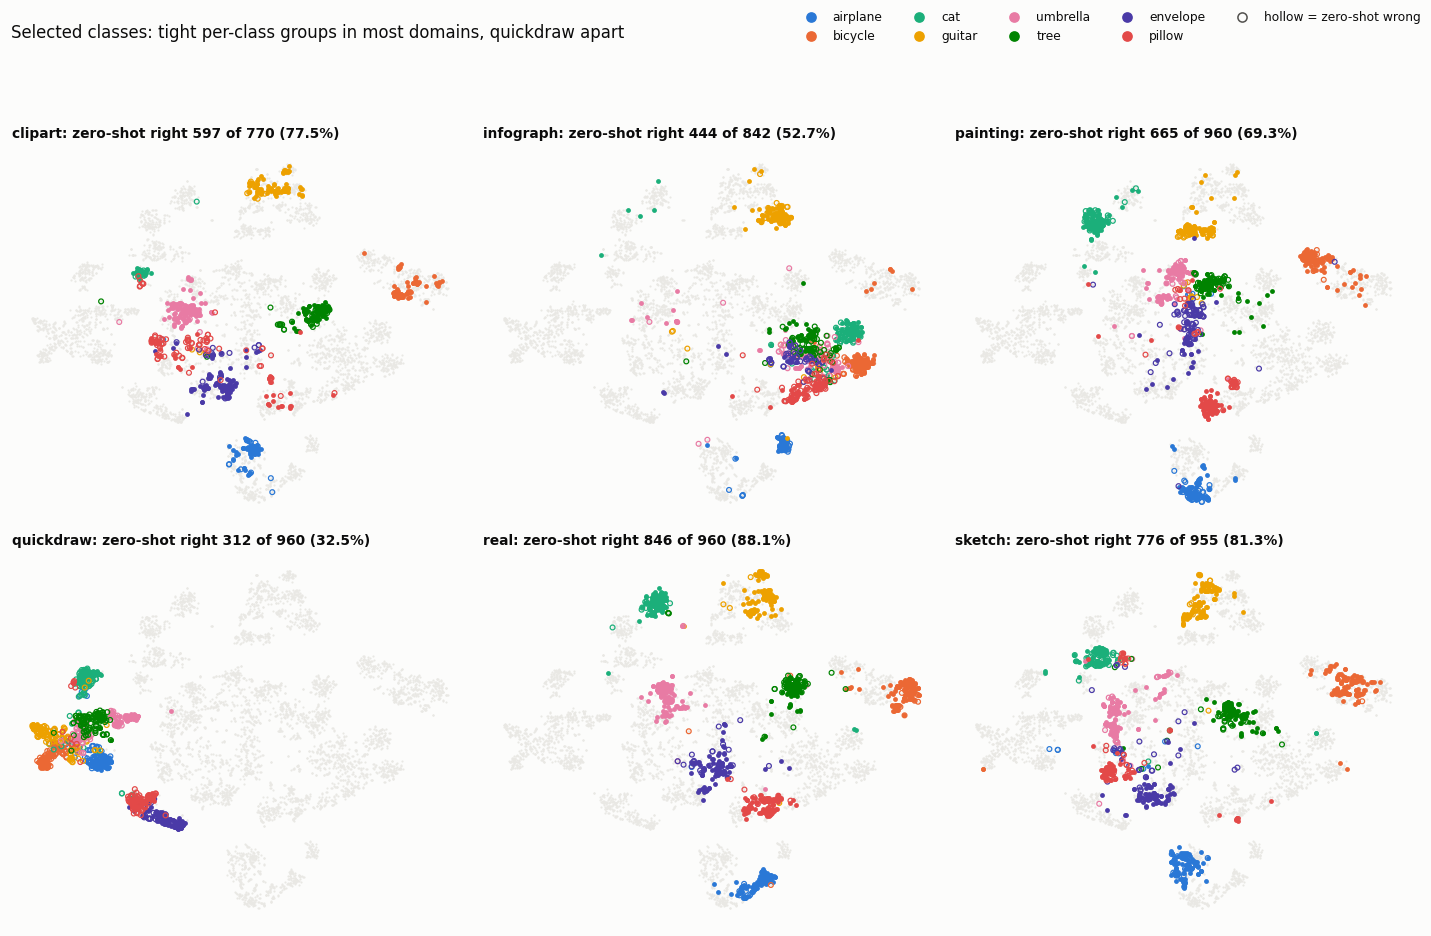

In [8]:
idx_c = stratified_sample(d, classes=CLASSES, per_cell=PER_CELL)
proj_cls = Projection(d).fit(idx_c)
fig = plots.class_panels(proj_cls, d, CLASSES, 'Selected classes: tight per-class groups in most domains, quickdraw apart')

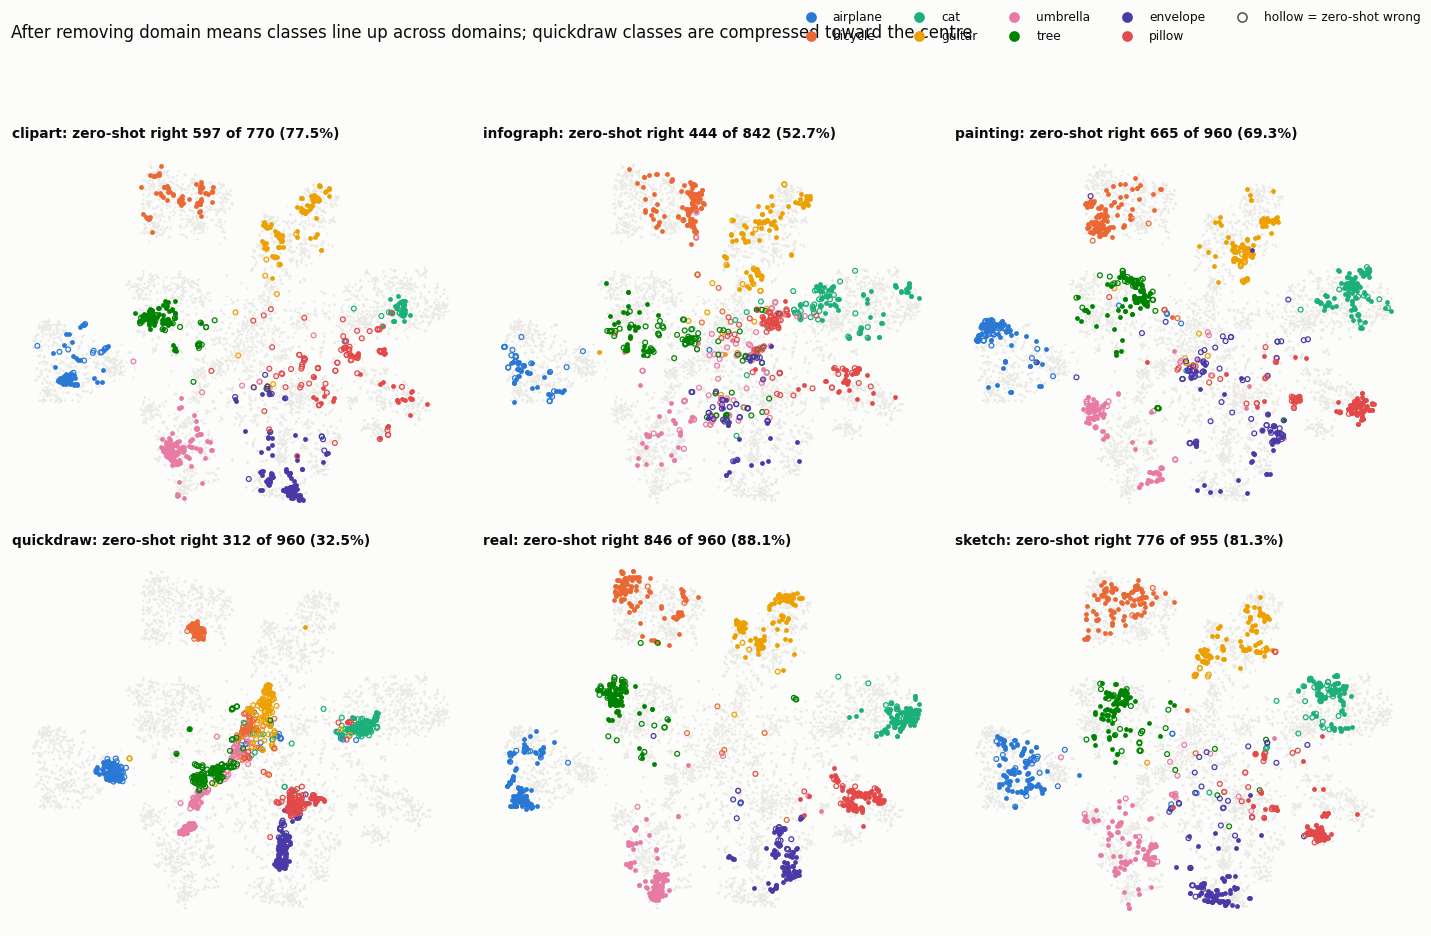

In [9]:
proj_cls_c = Projection(d, centre_domains=True).fit(idx_c)
fig = plots.class_panels(proj_cls_c, d, CLASSES, 'After removing domain means classes line up across domains; quickdraw classes are compressed toward the centre')

## 5. Domain geometry in the full 512-d space

In [10]:
g = Geometry(d)
display(g.variance_shares())
display(g.concentration())

,groups,share_of_variance
grouping,,
domain,6,15.80
class,345,18.61
class x domain cell,2070,43.18


,mean_resultant_length,offset_from_grand_mean
clipart,0.768,0.165
infograph,0.668,0.324
painting,0.722,0.239
quickdraw,0.924,0.391
real,0.691,0.199
sketch,0.754,0.140


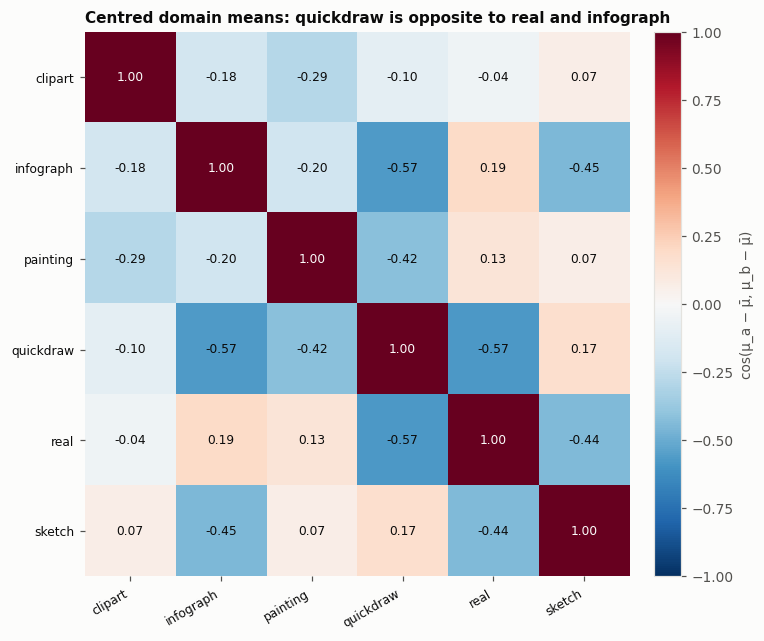

In [11]:
fig = plots.heatmap(g.centroid_similarity(), 'Centred domain means: quickdraw is opposite to real and infograph',
                   cmap='RdBu_r', vmin=-1, vmax=1, label='cos(μ_a − μ̄, μ_b − μ̄)')

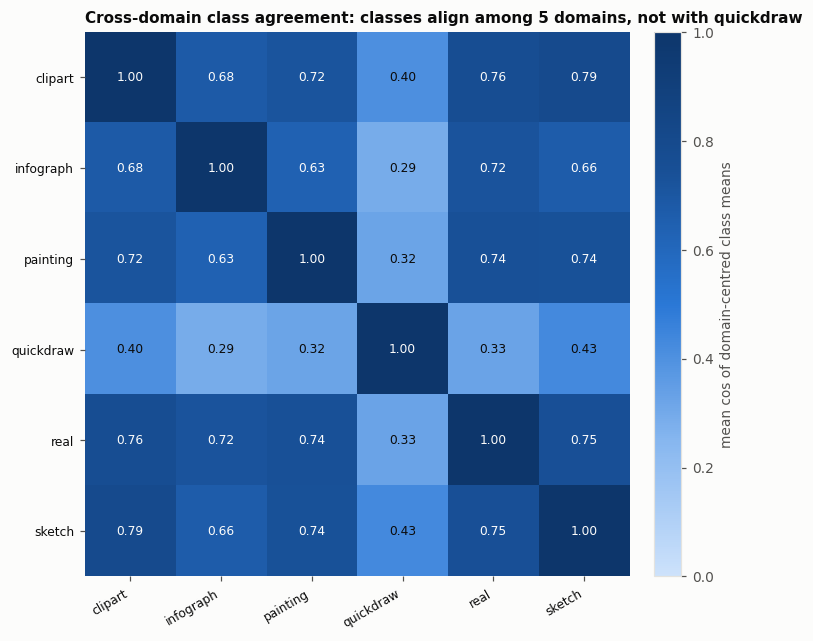

In [12]:
fig = plots.heatmap(g.class_agreement(), 'Cross-domain class agreement: classes align among 5 domains, not with quickdraw',
                   vmin=0, vmax=1, label='mean cos of domain-centred class means')

,classes,centroid_correct,centroid_acc,image_acc
domain,,,,
clipart,338,320,94.67,68.25
infograph,335,292,87.16,43.90
painting,316,300,94.94,64.58
quickdraw,345,58,16.81,13.33
real,345,341,98.84,82.12
sketch,342,325,95.03,60.05


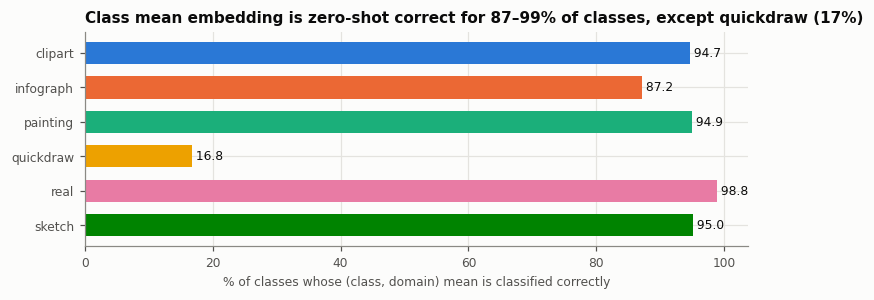

In [13]:
cz = g.centroid_zero_shot()
display(cz)
fig = plots.domain_bars(cz.centroid_acc, 'Class mean embedding is zero-shot correct for 87–99% of classes, except quickdraw (17%)',
                         '% of classes whose (class, domain) mean is classified correctly')

linear domain probe accuracy: 86.92% on 12,000 held-out images (chance 16.7%)


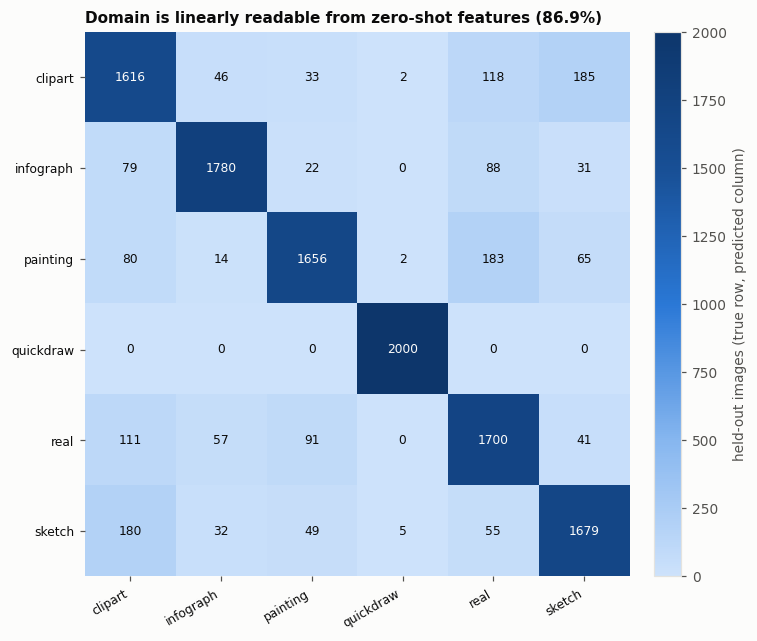

In [14]:
acc, cm = domain_probe(d)
print(f'linear domain probe accuracy: {100 * acc:.2f}% on {cm.values.sum():,} held-out images (chance 16.7%)')
fig = plots.heatmap(cm, f'Domain is linearly readable from zero-shot features ({100 * acc:.1f}%)', fmt='{:.0f}',
                   label='held-out images (true row, predicted column)')

## 6. Nearest neighbours in the full embedding

1,000 query images per domain, their K nearest neighbours among all 596,006 images. This is the geometry Ramen's memory retrieval sees.

,queries,"same class, same domain","same class, other domain","other class, same domain","other class, other domain",same-domain chance,zero-shot acc (queries),kNN-vote acc (oracle)
domain,,,,,,,,
clipart,1000,39.13,21.70,23.11,16.06,8.19,66.3,69.8
infograph,1000,22.48,10.57,55.21,11.74,8.93,42.2,45.7
painting,1000,43.35,15.51,29.75,11.39,12.71,68.9,70.4
quickdraw,1000,33.53,0.01,66.45,0.01,28.94,12.9,47.5
real,1000,70.88,6.12,17.92,5.08,29.42,81.1,83.8
sketch,1000,39.69,12.34,35.06,12.91,11.81,60.1,63.0


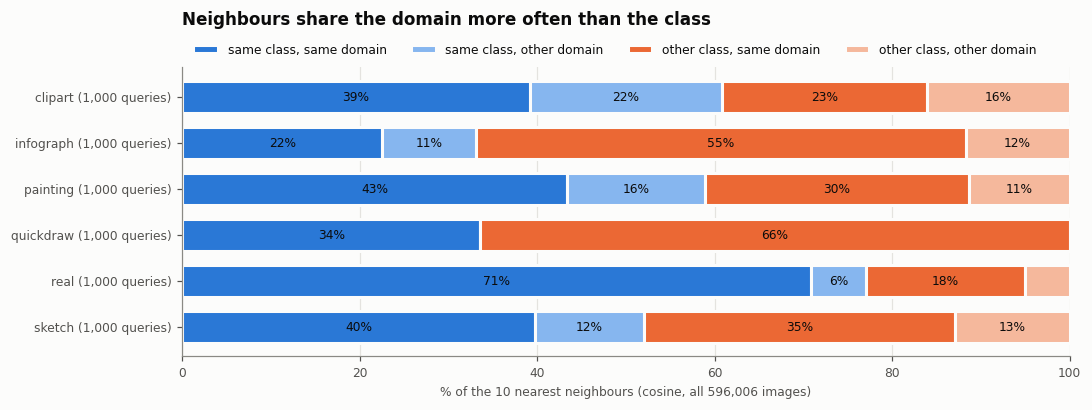

In [15]:
nb = Neighbours(d, k=K)
comp = nb.composition()
display(comp)
fig = plots.neighbour_bars(comp, k=K)

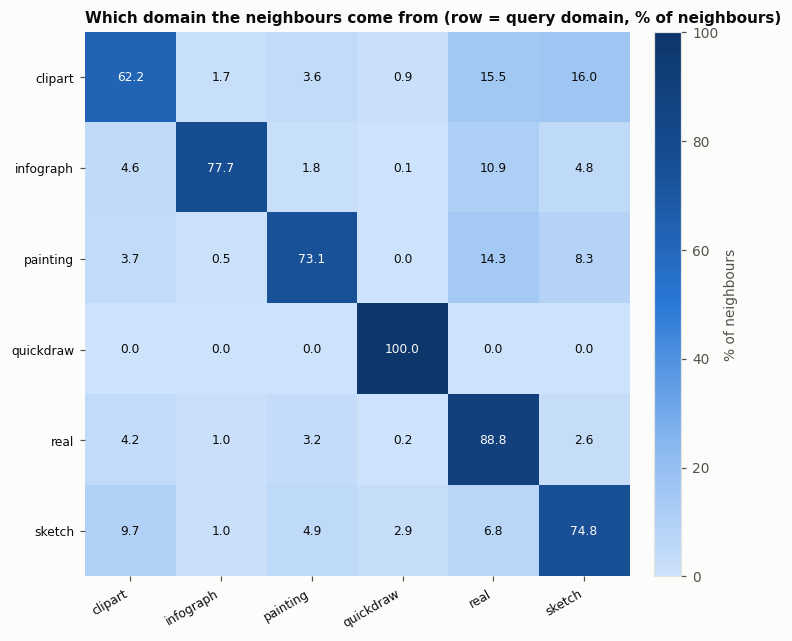

In [16]:
fig = plots.heatmap(nb.domain_mixing(), 'Which domain the neighbours come from (row = query domain, % of neighbours)',
                   fmt='{:.1f}', vmin=0, vmax=100, label='% of neighbours')

## 7. Image–text alignment

,images,cos_true_text,cos_best_wrong_text,mean_margin,share_margin_below_0,cos_domain_mean_to_text_mean
domain,,,,,,
clipart,48833,0.2762,0.2614,0.0148,31.7265,0.2745
infograph,53201,0.2229,0.2304,-0.0075,56.1004,0.2684
painting,75759,0.2636,0.2520,0.0116,35.4044,0.2810
quickdraw,172500,0.2635,0.2961,-0.0326,86.6858,0.2837
real,175327,0.2827,0.2536,0.0291,17.8752,0.2856
sketch,70386,0.2729,0.2655,0.0074,39.9611,0.2879


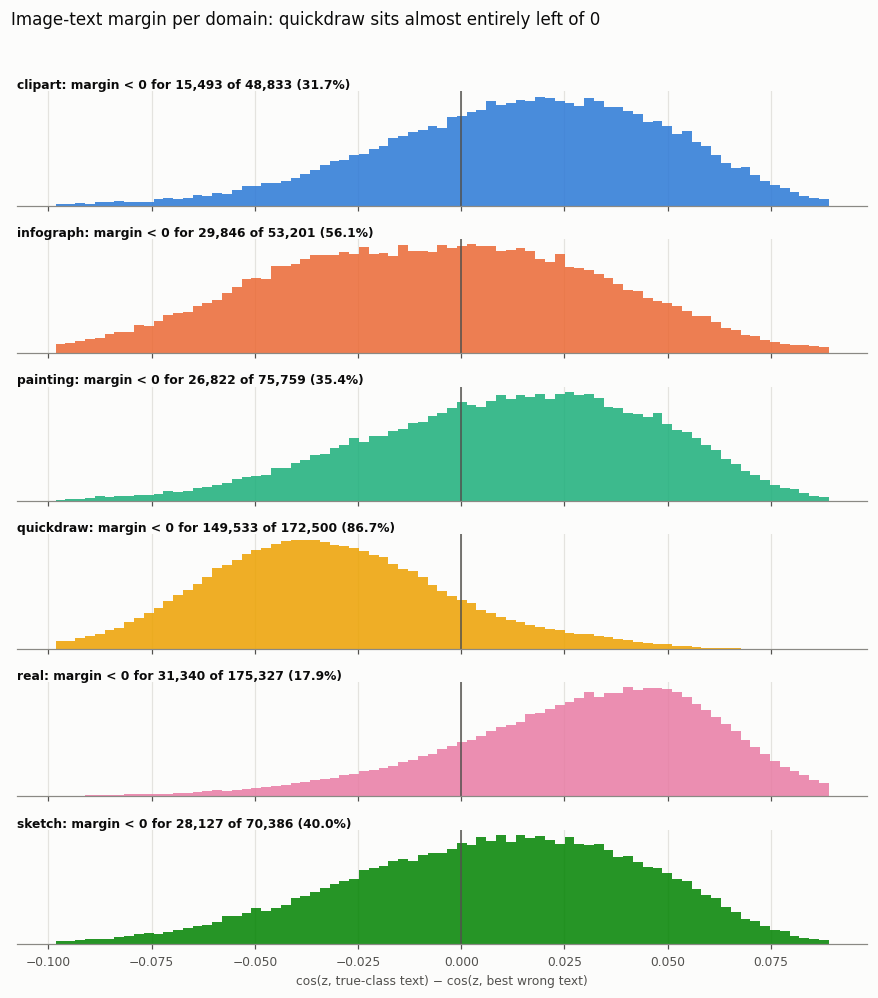

In [17]:
ta = TextAlignment(d)
display(ta.per_domain())
fig = plots.margin_distributions(ta.frame(np.arange(len(d))), d)

In [18]:
for dom in ['quickdraw', 'infograph']:
    pairs, sinks = top_confusions(d, dom)
    print(f'--- {dom}: top confusions and most-predicted classes'); display(pairs); display(sinks.to_frame())

--- quickdraw: top confusions and most-predicted classes


,count,share_of_domain_errors
"(ocean, squiggle)",480,0.32
"(tornado, squiggle)",467,0.31
"(river, squiggle)",457,0.31
"(hurricane, squiggle)",443,0.30
"(snake, squiggle)",439,0.29
"(square, envelope)",430,0.29
"(grass, squiggle)",427,0.29
"(zigzag, squiggle)",401,0.27
"(roller_coaster, squiggle)",397,0.27
"(beach, squiggle)",392,0.26


,predicted_count
squiggle,43917
envelope,13833
pear,7048
boomerang,4956
smiley_face,4590
triangle,3139
mushroom,2592
circle,2555
tooth,2376
toe,2163


--- infograph: top confusions and most-predicted classes


,count,share_of_domain_errors
"(table, spreadsheet)",292,0.98
"(goatee, beard)",140,0.47
"(van, spreadsheet)",118,0.40
"(telephone, cell_phone)",115,0.39
"(wine_glass, wine_bottle)",105,0.35
"(toothpaste, toothbrush)",102,0.34
"(zigzag, spreadsheet)",87,0.29
"(tooth, toothbrush)",83,0.28
"(tooth, toothpaste)",81,0.27
"(toothbrush, toothpaste)",73,0.24


,predicted_count
spreadsheet,2933
map,1432
calendar,1121
animal_migration,924
cell_phone,801
yoga,733
toothbrush,655
hockey_stick,621
light_bulb,573
brain,534


## 8. Classes × domains

Zero-shot accuracy per (class, domain): the 15 classes with the largest spread across all six domains (all near 0% on quickdraw), the 15 with the smallest, and the 15 with the largest spread when quickdraw is left out.

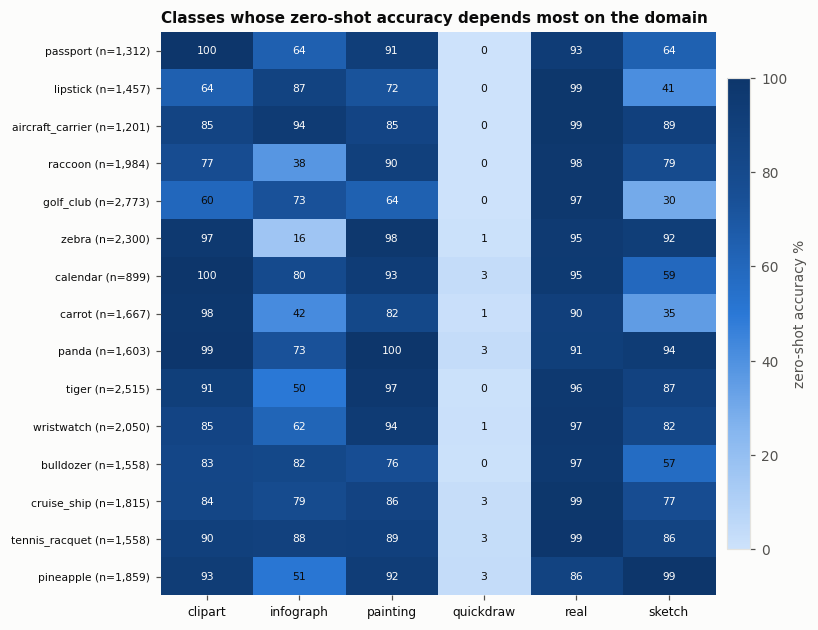

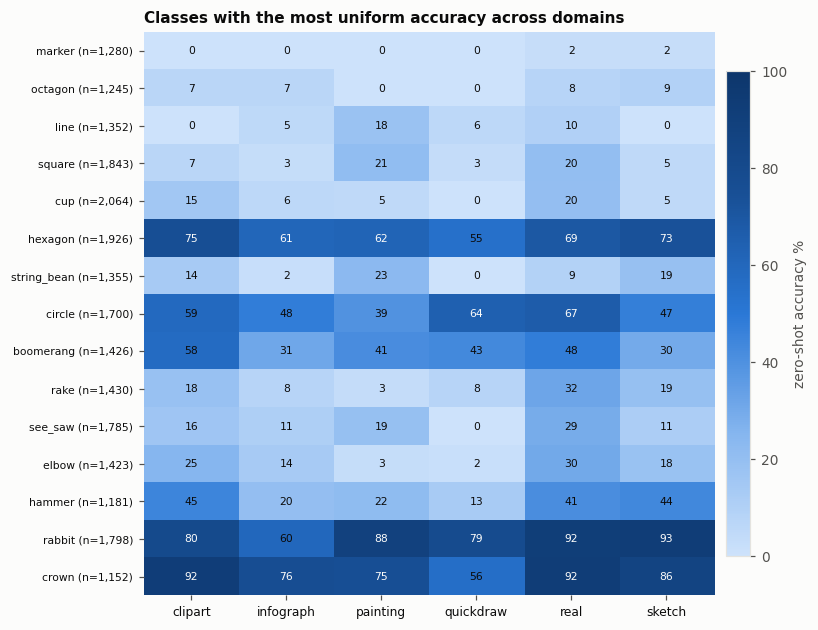

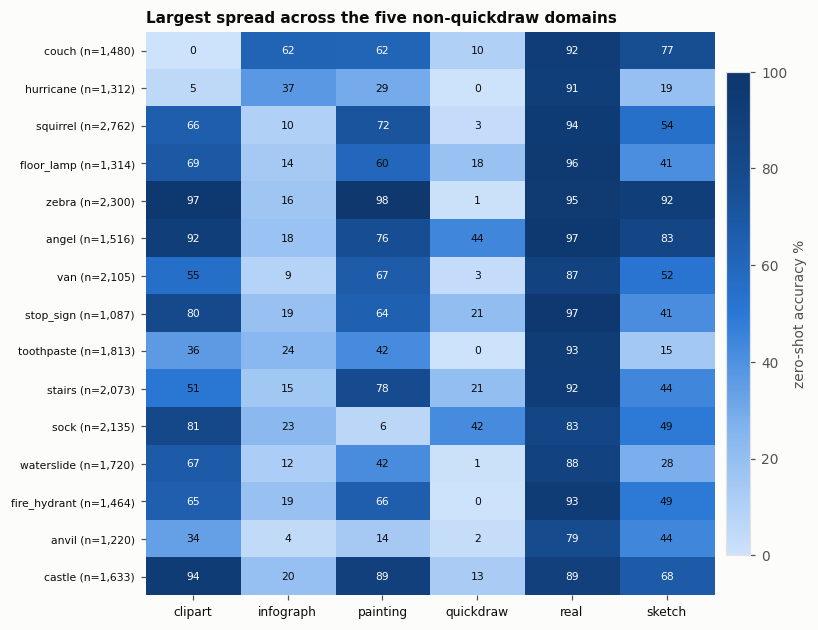

In [19]:
acc_cd, n_cd = g.class_domain_accuracy()
spread = acc_cd.max(1) - acc_cd.min(1)
fig = plots.class_domain_heatmap(acc_cd, n_cd, list(spread.sort_values().index[-15:][::-1]),
                                 'Classes whose zero-shot accuracy depends most on the domain')
fig = plots.class_domain_heatmap(acc_cd, n_cd, list(spread.sort_values().index[:15]),
                                 'Classes with the most uniform accuracy across domains')
five = [c for c in d.domains if c != 'quickdraw']
spread5 = acc_cd[five].max(1) - acc_cd[five].min(1)
fig = plots.class_domain_heatmap(acc_cd, n_cd, list(spread5.sort_values().index[-15:][::-1]),
                                 'Largest spread across the five non-quickdraw domains')

## 9. Images

Random images of a true class in every domain, captioned with the zero-shot prediction (✗ = wrong).

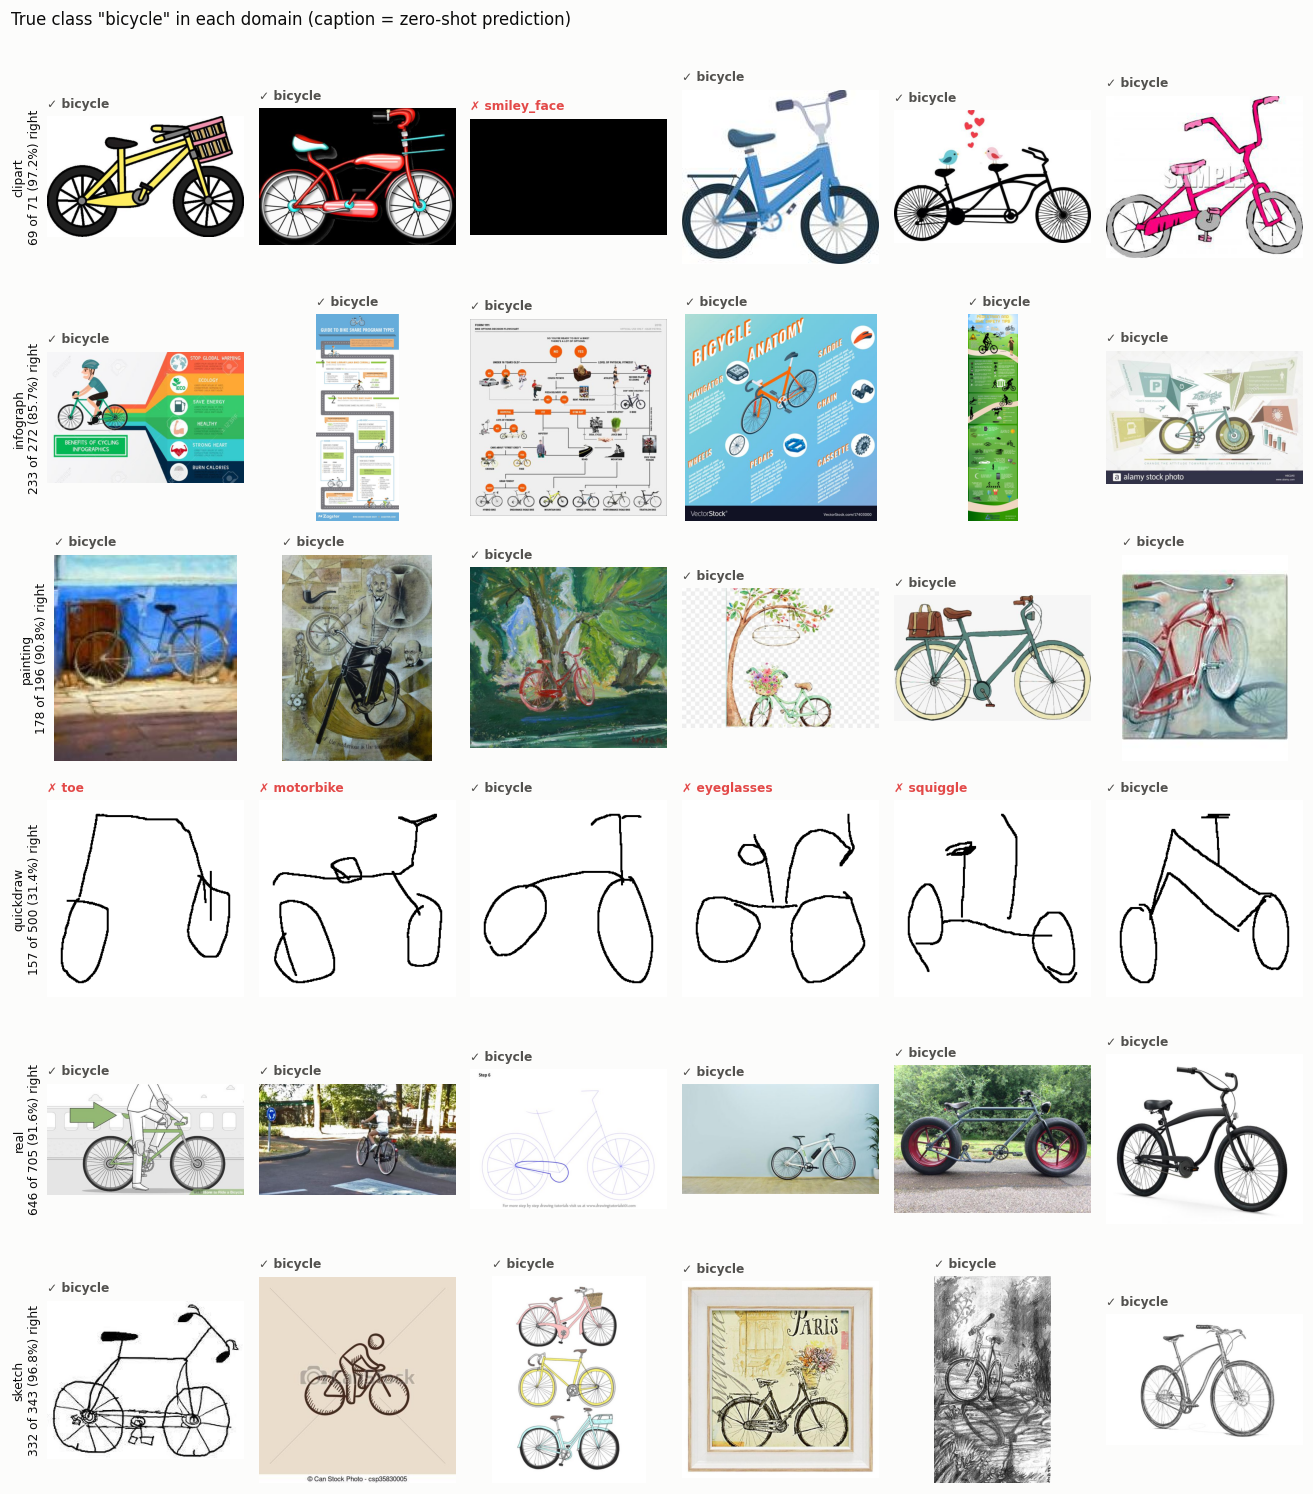

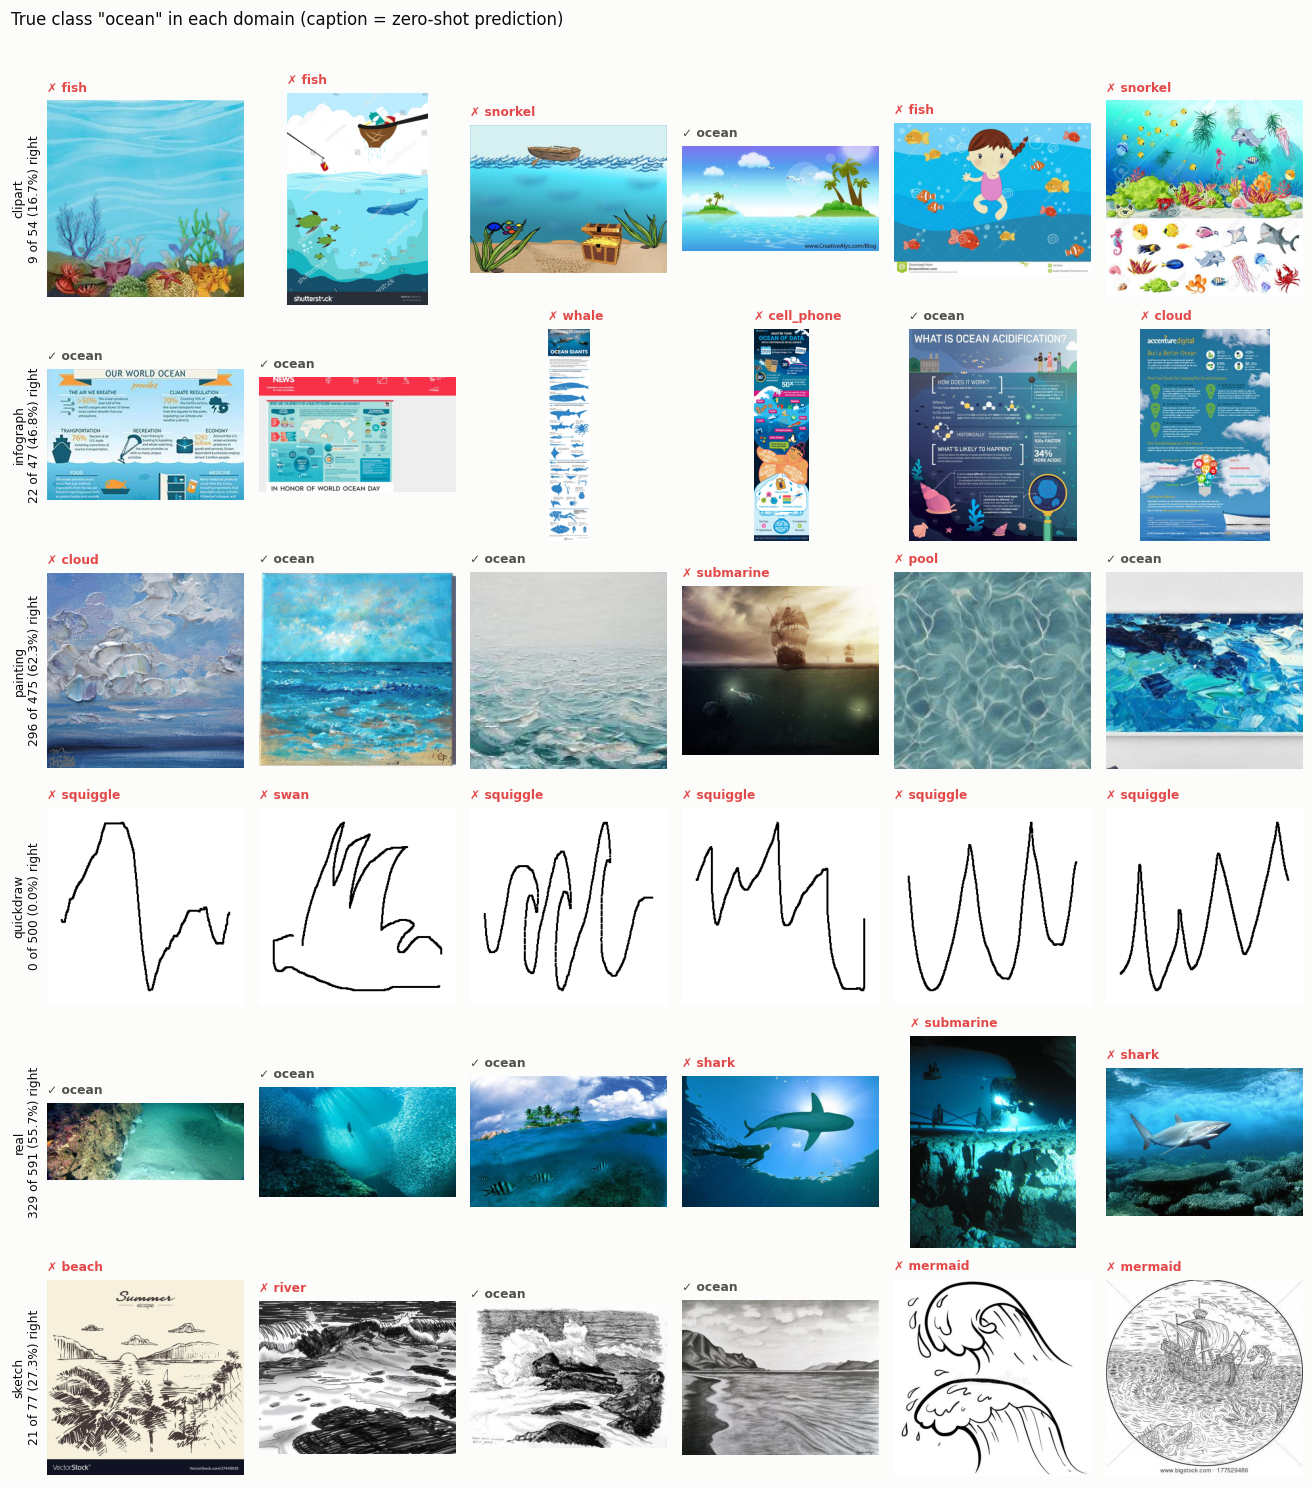

In [20]:
for cls in GRID_CLASSES:
    fig = plots.image_grid(d, cls, per_domain=6)
    plt.show()

## 10. Interpretation

**What the numbers say.**
1. **Domain is a first-class axis of the zero-shot embedding.** Domain alone explains 15.8% of the variance of $z$, about as much as the
   345 classes (18.6%); class × domain cells explain 43.2%, more than the two separately (34.4%), so a class's position depends on the
   domain. A linear probe reads the domain from $z$ with 86.9% accuracy (chance 16.7%), and quickdraw with 2,000 of 2,000.
2. **Neighbourhoods are organised by domain first.** Across the five non-quickdraw domains, 62–89% of the 10 nearest neighbours are in the
   query's own domain (chance 8–29%), and "other class, same domain" neighbours (18–55%) outnumber "same class, other domain"
   ones (6–22%) everywhere except clipart. Infograph is the worst: 55% of neighbours are other classes from infograph.
   **But much of this is a per-domain offset:** after subtracting each domain's mean (domain-centred t-SNE) the domains mostly mix and
   the selected classes land in the same regions in every domain; domain-centred class means agree at cosine 0.63–0.79 across the five
   non-quickdraw domains.
3. **Quickdraw is a separate island, shifted and compressed.** 100.0% of quickdraw's neighbours are quickdraw images; its domain mean
   has the highest concentration (mean resultant length 0.92: every drawing points almost the same way) and the largest offset from the
   grand mean (0.39). After centring, quickdraw classes sit roughly in the same regions as in other domains (airplane, cat, envelope,
   pillow) but compressed toward the centre, with bicycle / guitar / tree / umbrella collapsing together; class agreement with the other
   domains is lower (0.29–0.43) but positive.
4. **Elsewhere the error is per-image scatter, not a moved class; in quickdraw the whole class moves.** The mean feature of a class is
   zero-shot correct for 87–99% of classes in the five other domains, although only 44–82% of images are. In quickdraw only 58 of 345 class
   centroids (16.8%) are correct: averaging the images does not help, because the class prototype itself points at the wrong text.
   Quickdraw errors are dominated by sinks: 43,917 of 172,500 quickdraw images (25.5%) are predicted "squiggle", 13,833 "envelope".
5. **The information is there in the image geometry.** A 10-NN vote with true labels (oracle) reaches 47.5% on quickdraw against 12.9%
   zero-shot for the same queries; on the other domains the vote is only +1.5 to +3.5 above zero-shot. So in quickdraw images of a class
   do cluster together (33.5% same-class neighbours), but that cluster does not point at its text embedding: a large part of quickdraw's
   loss is in the image-to-text matching. Elsewhere the oracle vote barely beats zero-shot, so the text side is not the main limit there.
6. **Image–text alignment is uniformly weak in absolute terms.** True-class cosines are 0.22–0.28 in every domain; the margin to the best wrong
   text is a few hundredths. Infograph has the lowest true-class cosine (0.223) and quickdraw the highest best-wrong cosine (0.296: a few
   generic texts such as "squiggle" match all line drawings).

**What it doesn't say.** These are zero-shot features only (no Ramen); t-SNE pictures are qualitative (one perplexity, 9,000 points);
variance shares are on raw cosine geometry and depend on the domain sizes (quickdraw and real are 58% of all images).

**Link to the Ramen findings.** Point 4 is the image-level picture behind the shift-decomposition result that concept shift (Γ) is the large
oracle component on DomainNet and mostly quickdraw, and behind the squiggle/envelope/pillow sinks in the confusion records. Point 2 explains why
Ramen's memory retrieval (nearest neighbours by $z$) mostly brings back same-domain, often other-class entries.

**Possible next steps.** (a) Same figures for Ramen's adapted features (`Ramen_feats.npy` is cached) to see whether adaptation moves
quickdraw toward its text; (b) per-domain text prompts ("a drawing of a …") as a zero-cost test of whether quickdraw's failure is a
text-side mismatch, as point 5 suggests.


## 11. Glossary

- **Zero-shot / NoAdapt**: frozen CLIP, predict the class whose text embedding has the highest cosine with the image embedding.
- **Domain**: the rendering style of DomainNet images (clipart, infograph, painting, quickdraw, real, sketch); the 345 classes are shared.
- **t-SNE**: a 2-D map that keeps each point's nearest neighbours near; gaps and sizes of clusters are not to scale.
- **Domain-centred**: each image embedding minus the mean embedding of its domain.
- **Variance share (η²)**: fraction of the total spread of the embeddings explained by the group means.
- **Mean resultant length**: length of the average unit vector; close to 1 when all vectors point the same way.
- **Linear probe**: a logistic regression trained on frozen embeddings, here to predict the domain.
- **Class agreement**: cosine between the same class's domain-centred mean embeddings in two domains.
- **Centroid zero-shot accuracy**: whether the mean embedding of a class in a domain is classified as that class.
- **Margin**: true-class text cosine minus the best wrong-class text cosine; negative means a zero-shot error.
- **Sink**: a class that zero-shot predicts far more often than it occurs (squiggle, envelope on quickdraw).
- **Oracle**: uses ground-truth labels; a measurement, not a method.
- **Modality gap**: image and text embeddings of CLIP occupy different regions of the sphere, so raw image–text cosines are small (~0.2–0.3).
